In [1]:
import numpy as np
import pandas as pd

X_test = pd.read_csv("../../data/processed/X_test_processed.csv")
y_train = pd.read_csv("../../data/processed/y_train.csv")
y_test = pd.read_csv("../../data/processed/y_test.csv")
X_train = pd.read_csv("../../data/processed/X_train_processed.csv")

X_train

,numeric__Age,numeric__Job,numeric__Credit amount,numeric__Duration,categorical__Sex_female,categorical__Sex_male,categorical__Housing_free,categorical__Housing_own,categorical__Housing_rent,categorical__Saving accounts_little,...,categorical__Checking account_moderate,categorical__Checking account_rich,categorical__Purpose_business,categorical__Purpose_car,categorical__Purpose_domestic appliances,categorical__Purpose_education,categorical__Purpose_furniture/equipment,categorical__Purpose_radio/TV,categorical__Purpose_repairs,categorical__Purpose_vacation/others
0,0.793959,-1.427676,1.020327,-0.219973,0.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,1.615804,0.117454,-0.295809,0.278807,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.941046,-1.427676,-0.329582,-0.469362,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.210518,0.117454,-0.085157,-0.469362,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.976592,1.662584,-0.277703,0.029417,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
758,-1.032363,0.117454,1.144281,2.273924,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
759,-1.123679,0.117454,-0.983820,-1.217531,1.0,0.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
760,0.063431,1.662584,-0.316003,-0.718752,0.0,1.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
761,0.793959,0.117454,-0.734869,-0.718752,0.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

def evaluate_model(model, X_test, y_test):

    predictions = model.predict(X_test)

    probabilities = model.predict_proba(X_test)[:, 1]

    print("Accuracy:",
          accuracy_score(y_test, predictions))

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, predictions))

    print("\nROC-AUC:",
          roc_auc_score(y_test, probabilities))

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

# 1. Initialize the model
model = KNeighborsClassifier()

# 2. Set up the parameter grid (no 'classifier__' prefix needed without a Pipeline)
param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

# 3. Run GridSearchCV
grid = GridSearchCV(model, param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train.values.ravel())

print("Best parameters:", grid.best_params_)

# 4. Evaluate the best model on X_test
best_model = grid.best_estimator_
evaluate_model(best_model, X_test, y_test.values.ravel())

Best parameters: {'n_neighbors': 21, 'p': 2, 'weights': 'uniform'}
Accuracy: 0.6963350785340314

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.96      0.82       133
           1       0.50      0.09      0.15        58

    accuracy                           0.70       191
   macro avg       0.60      0.52      0.48       191
weighted avg       0.64      0.70      0.61       191


Confusion Matrix:
[[128   5]
 [ 53   5]]

ROC-AUC: 0.6416904329789992


In [4]:
train_probs = best_model.predict_proba(X_train)[:, 1]
print("Train ROC-AUC:", roc_auc_score(y_train, train_probs))
print("Test ROC-AUC:", roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1]))

Train ROC-AUC: 0.7338760863196954
Test ROC-AUC: 0.6416904329789992


In [5]:
train_auc = roc_auc_score(y_train, best_model.predict_proba(X_train)[:, 1])
test_auc = roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1])
diff = train_auc - test_auc

print(f"Train ROC-AUC: {train_auc:.2%}")
print(f"Test ROC-AUC:  {test_auc:.2%}")
print(f"Difference:    {diff:.2%}")

Train ROC-AUC: 73.39%
Test ROC-AUC:  64.17%
Difference:    9.22%


In [6]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Get predicted probabilities for Class 1
probs = best_model.predict_proba(X_test)[:, 1]
y_true = y_test.values.ravel()

print(f"{'Threshold':<10} {'Recall (Class 1)':<18} {'Precision (Class 1)':<20} {'F1-Score':<10}")
print("-" * 60)

for thresh in np.arange(0.10, 0.55, 0.05):
    preds = (probs >= thresh).astype(int)
    rec = recall_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    f1 = f1_score(y_true, preds)
    print(f"{thresh:<10.2f} {rec:<18.2%} {prec:<20.2%} {f1:<10.2%}")

Threshold  Recall (Class 1)   Precision (Class 1)  F1-Score  
------------------------------------------------------------
0.10       93.10%             32.14%               47.79%    
0.15       86.21%             33.56%               48.31%    
0.20       75.86%             36.97%               49.72%    
0.25       56.90%             37.93%               45.52%    
0.30       48.28%             44.44%               46.28%    
0.35       37.93%             52.38%               44.00%    
0.40       32.76%             55.88%               41.30%    
0.45       20.69%             50.00%               29.27%    
0.50       8.62%              50.00%               14.71%    


In [7]:
from sklearn.metrics import classification_report, confusion_matrix

best_thresh = 0.30  # <-- replace with your chosen threshold from the table above
final_preds = (probs >= best_thresh).astype(int)

print(f"Results at threshold = {best_thresh}:")
print(classification_report(y_true, final_preds))
print("Confusion Matrix:\n", confusion_matrix(y_true, final_preds))

Results at threshold = 0.3:
              precision    recall  f1-score   support

           0       0.77      0.74      0.75       133
           1       0.44      0.48      0.46        58

    accuracy                           0.66       191
   macro avg       0.61      0.61      0.61       191
weighted avg       0.67      0.66      0.66       191

Confusion Matrix:
 [[98 35]
 [30 28]]


Optimal Threshold: 0.2381
Best F1-Score:     49.72%
Precision:         36.97%
Recall:            75.86%


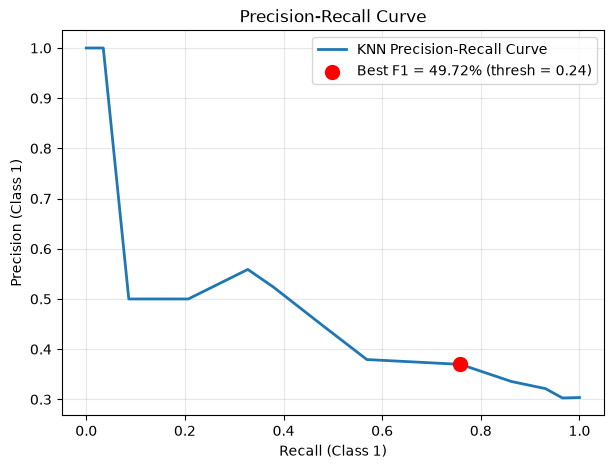


Classification Report (Optimal Threshold):
              precision    recall  f1-score   support

           0       0.81      0.44      0.57       133
           1       0.37      0.76      0.50        58

    accuracy                           0.53       191
   macro avg       0.59      0.60      0.53       191
weighted avg       0.67      0.53      0.54       191

Confusion Matrix:
 [[58 75]
 [14 44]]


In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix

# 1. Get probabilities and true labels
probs = best_model.predict_proba(X_test)[:, 1]
y_true = y_test.values.ravel()

# 2. Compute Precision-Recall pairs for every threshold
precision, recall, thresholds = precision_recall_curve(y_true, probs)

# 3. Calculate F1-score for each threshold (slice [:-1] to match thresholds length)
p = precision[:-1]
r = recall[:-1]
f1_scores = np.divide(2 * p * r, p + r, out=np.zeros_like(p), where=(p + r) != 0)

# 4. Find the threshold that maximizes F1-score
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Optimal Threshold: {best_thresh:.4f}")
print(f"Best F1-Score:     {best_f1:.2%}")
print(f"Precision:         {p[best_idx]:.2%}")
print(f"Recall:            {r[best_idx]:.2%}")

# 5. Plot the Precision-Recall curve
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label="KNN Precision-Recall Curve", linewidth=2)
plt.scatter(
    r[best_idx],
    p[best_idx],
    color="red",
    s=100,
    zorder=5,
    label=f"Best F1 = {best_f1:.2%} (thresh = {best_thresh:.2f})"
)
plt.xlabel("Recall (Class 1)")
plt.ylabel("Precision (Class 1)")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("../../reports/figures/knn_precision_recall_curve.png", dpi=300, bbox_inches="tight")

plt.show()

# 6. Evaluate using the optimal threshold
optimal_preds = (probs >= best_thresh).astype(int)
print("\nClassification Report (Optimal Threshold):")
print(classification_report(y_true, optimal_preds))
print("Confusion Matrix:\n", confusion_matrix(y_true, optimal_preds))